# Automated Malaria Parasite Detection in Thin Blood Smears Using a CNN
## Submission 3 — Custom CNN from scratch

**Course:** CSE366 Artificial Intelligence  **Group:** 6

| Name | Student ID |
|---|---|
| Tahmid Aqib | 2024-1-60-225 |
| Rejoanur Rahman | 2024-1-60-245 |
| Mahmudur Rahaman Pial | 2024-1-60-177 |
| Sayem Siddiq | 2024-1-60-298 |

**Contents**
1. Design overview: architecture, preprocessing, hyperparameters
2. Setup and configuration
3. Data: Submission 1 split, imported `Dataset`, transforms and loaders
4. The custom CNN
5. Training with early stopping
6. Learning curves and over/underfitting check
7. Test-set evaluation: metrics, confusion matrix, timing
8. Error analysis: missed infections and false alarms
9. Supplementary: clinical operating point
10. Comparison with the Submission 2 pretrained models
11. Evaluation report

## 1. Design overview

**Goal.** Design and train a CNN **from random initialisation** (no pretrained weights) that classifies single red-blood-cell images as `Parasitized` or `Uninfected`. We evaluate it with the same metrics and the same test images as the pretrained models in Submission 2, so the two approaches can be compared directly.

### Architecture

Four convolutional blocks, each doubling the number of channels and halving the spatial size, followed by global average pooling and a fully connected classifier.

| Stage | Layers | Output shape (C × H × W) |
|---|---|---|
| Input | RGB cell image, padded to square and resized | 3 × 128 × 128 |
| Block 1 | [Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool 2×2 | 32 × 64 × 64 |
| Block 2 | [Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool 2×2 | 64 × 32 × 32 |
| Block 3 | [Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool 2×2 | 128 × 16 × 16 |
| Block 4 | [Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool 2×2 | 256 × 8 × 8 |
| Head | Global average pool → Dropout 0.5 → FC 256→128 → ReLU → Dropout 0.3 → **FC 128→2** | 2 logits |

**Why this design**
* **Stacked 3×3 convolutions** (VGG style). Two 3×3 layers see the same 5×5 area as one 5×5 layer, but with fewer parameters and an extra non-linearity. After four blocks, each output feature "sees" the whole cell, so a parasite anywhere in the cell can be detected.
* **Batch normalisation after every convolution** keeps the activations well scaled, which allows a higher learning rate and faster, more stable training from scratch. Convolutions feeding BatchNorm use `bias=False`, because BatchNorm already adds its own shift.
* **ReLU** activations are cheap, and they avoid the vanishing gradients of sigmoid and tanh.
* **Max pooling** halves the resolution after each block. It keeps the strongest response (for example, the dark purple parasite) and makes the network tolerant to small shifts.
* **Global average pooling instead of flattening.** Flattening 256 × 8 × 8 would need about 2 M weights in the first fully connected layer; global pooling needs 256 inputs. That makes the model much smaller and less prone to overfitting, and the result is the same wherever the parasite sits in the cell.
* **Fully connected classifier with dropout**, ending in a 2-unit FC layer, as the syllabus requires.
* **Size: about 1.2 M parameters**, about half of MobileNetV2 and about 20× smaller than ResNet-50, which suits a simple two-class texture problem.

### Preprocessing and augmentation (from the Submission 1 EDA)

| Step | Train | Val / Test | Reason |
|---|---|---|---|
| Pad to square with black, resize to **128×128** | ✓ | ✓ | Cell crops vary in size; padding keeps cells round. 128 px keeps parasite detail at a low compute cost |
| Random rotation 0–360°, horizontal and vertical flips | ✓ | | Cells have no natural orientation |
| Small shift (±5%) and zoom (±5%) | ✓ | | Robust to segmentation and cropping differences |
| Mild brightness / contrast / saturation / hue jitter | ✓ | | Stain and exposure vary between slides |
| Normalise with **our training-set mean/std** | ✓ | ✓ | The network learns from scratch, so we use our own data statistics (computed on the train split only in Submission 1), not ImageNet's |

### Hyperparameters (fixed and saved to `results/sub3/config.json` for reproducibility)

| Setting | Value |
|---|---|
| Batch size | 64 |
| Optimiser | AdamW, learning rate 1e-3, weight decay 1e-4 |
| Loss | Cross-entropy |
| LR schedule | ReduceLROnPlateau on validation loss (factor 0.3, patience 3) |
| Epochs | up to 100; **early stopping** after 8 epochs without val-loss improvement, **never before epoch 5** |
| Model selection | Weights from the epoch with the lowest validation loss are restored before testing |
| Precision | Mixed precision (FP16 autocast + gradient scaling), channels-last |
| Seed | 42 |

## 2. Setup

In [1]:
import os, sys, json, time, random, platform, gc, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

if torch.cuda.is_available():
    device = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
else:
    device = torch.device("cpu")
    print("WARNING: CUDA not available — training on CPU will be slow.")

torch.backends.cudnn.benchmark = True          # fastest conv algorithms for fixed 128x128 inputs
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
USE_AMP = device.type == "cuda"

print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")

GPU: NVIDIA GeForce RTX 4070 | VRAM: 11.6 GB | CUDA 13.2
Python 3.15.2 | torch 2.15.0+cu132 | torchvision 0.29.2+cu132


In [2]:
# ---- configuration (one place for every hyperparameter; saved to results/sub3/config.json) ----
SEED          = 42
IMG_SIZE      = 128
BATCH_SIZE    = 64
EVAL_BATCH    = 128
NUM_WORKERS   = 6        # training loader workers
EVAL_WORKERS  = 4        # validation / test loader workers
PREFETCH      = 2        # batches queued per worker (keeps RAM use safe on 16 GB)
MAX_EPOCHS    = 100      # generous budget so early stopping (not the epoch limit) ends training
MIN_EPOCHS    = 5        # syllabus: train for at least 5 epochs before early stopping may trigger
PATIENCE      = 8        # epochs without val-loss improvement before stopping
LR            = 1e-3
WEIGHT_DECAY  = 1e-4
SCHED_FACTOR  = 0.3
SCHED_PATIENCE = 3
RETRAIN       = True     # True: always train; set False to reload a finished run saved on disk

# Training-set statistics from Submission 1 (pixels scaled to [0, 1])
NORM_MEAN = [0.5296, 0.4241, 0.4530]
NORM_STD  = [0.3359, 0.2717, 0.2871]

CLASSES      = ["Parasitized", "Uninfected"]   # index 0 = Parasitized (positive / disease class)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
RUN_NAME     = "custom_cnn"

SPLITS_CSV  = Path("./splits/splits.csv")
NORM_JSON   = Path("./splits/norm_stats.json")
CKPT_DIR    = Path("./checkpoints/sub3"); CKPT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("./results/sub3");     RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR     = Path("./figures/sub3");     FIG_DIR.mkdir(parents=True, exist_ok=True)

# Image folder: ./data if present, otherwise the kagglehub cache used in Submissions 1-2
if Path("./data").exists():
    DATA_DIR = Path("./data")
else:
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

CONFIG = {k: v for k, v in globals().items()
          if k in ["SEED", "IMG_SIZE", "BATCH_SIZE", "EVAL_BATCH", "NUM_WORKERS", "EVAL_WORKERS", "PREFETCH",
                   "MAX_EPOCHS", "MIN_EPOCHS", "PATIENCE", "LR", "WEIGHT_DECAY", "SCHED_FACTOR",
                   "SCHED_PATIENCE", "NORM_MEAN", "NORM_STD", "CLASSES"]}
json.dump(CONFIG, open(RESULTS_DIR / "config.json", "w"), indent=2)
print(json.dumps(CONFIG, indent=1))

{
 "SEED": 42,
 "IMG_SIZE": 128,
 "BATCH_SIZE": 64,
 "EVAL_BATCH": 128,
 "NUM_WORKERS": 6,
 "EVAL_WORKERS": 4,
 "PREFETCH": 2,
 "MAX_EPOCHS": 100,
 "MIN_EPOCHS": 5,
 "PATIENCE": 8,
 "LR": 0.001,
 "WEIGHT_DECAY": 0.0001,
 "SCHED_FACTOR": 0.3,
 "SCHED_PATIENCE": 3,
 "NORM_MEAN": [
  0.5296,
  0.4241,
  0.453
 ],
 "NORM_STD": [
  0.3359,
  0.2717,
  0.2871
 ],
 "CLASSES": [
  "Parasitized",
  "Uninfected"
 ]
}


## 3. Data

### 3.1 Load the Submission 1 split
We read `splits/splits.csv` unchanged. It is the leakage-safe split in which all cells from one smear photograph sit in the same subset. This is the same train, validation and test data used in Submission 2, so the results are directly comparable.

In [3]:
def find_class_root(root):
    # Return the shallowest folder that contains both class sub-folders.
    root = Path(root)
    candidates = [root] + sorted((d for d in root.rglob("*") if d.is_dir()), key=lambda p: len(p.parts))
    for p in candidates:
        if all((p / c).is_dir() for c in CLASSES):
            return p
    raise FileNotFoundError(f"No folder with {CLASSES} under {root.resolve()}")

IMG_ROOT = find_class_root(DATA_DIR)
splits = pd.read_csv(SPLITS_CSV)
assert {"relpath", "label", "split"} <= set(splits.columns), "splits.csv is missing required columns"
missing = [p for p in splits.relpath if not (IMG_ROOT / p).is_file()]
assert not missing, f"{len(missing)} files in splits.csv not found, e.g. {missing[:3]}"

train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df   = splits[splits.split == "val"].reset_index(drop=True)
test_df  = splits[splits.split == "test"].reset_index(drop=True)

print("Image root:", IMG_ROOT.resolve())
display(pd.crosstab(splits.split, splits.label, margins=True).reindex(["train", "val", "test", "All"]))

Image root: /home/taqib/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images


label,Parasitized,Uninfected,All
split,,,
train,9834,9827,19661
val,1973,1976,3949
test,1972,1976,3948
All,13779,13779,27558


### 3.2 Dataset class and transforms

`MalariaCellDataset` and `PadToSquare` are **imported from `malaria_data.py`**, the module written in Submission 2. They are not redefined here. On Python 3.14+ Linux, DataLoader worker processes start with *forkserver* and must import every class they receive, and a class defined only in a notebook cell cannot be imported. Re-using the module also guarantees that images are loaded exactly as in Submission 2.

Normalisation uses **our own training-set statistics**, not ImageNet's, because this network starts from random weights. The values below are cross-checked against `splits/norm_stats.json`.

In [4]:
assert Path("malaria_data.py").exists(), "malaria_data.py not found — run Submission 2 first or copy the file here."
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
import malaria_data
importlib.reload(malaria_data)
from malaria_data import MalariaCellDataset, PadToSquare
print("Imported from:", malaria_data.__file__)

# Cross-check the hard-coded statistics against the Submission 1 file
if NORM_JSON.exists():
    saved = json.load(open(NORM_JSON))
    diff = max(abs(a - b) for a, b in zip(saved["mean"] + saved["std"], NORM_MEAN + NORM_STD))
    print(f"norm_stats.json -> mean={saved['mean']}, std={saved['std']} | max difference: {diff:.4f}")
    if diff > 1e-3:
        print("WARNING: statistics differ from splits/norm_stats.json — check which values are correct.")

train_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=180, translate=(0.05, 0.05), scale=(0.95, 1.05), fill=0),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])
eval_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

Imported from: /home/taqib/Documents/cnnproject/malaria_data.py
norm_stats.json -> mean=[0.5296, 0.4241, 0.453], std=[0.3359, 0.2717, 0.2871] | max difference: 0.0000


### 3.3 Datasets and data loaders
Settings are tuned for 16 GB of system RAM: 6 training workers, 4 evaluation workers, a prefetch queue of 2 batches per worker, and pinned memory for fast host-to-GPU copies.

train=19,661  val=3,949  test=3,948


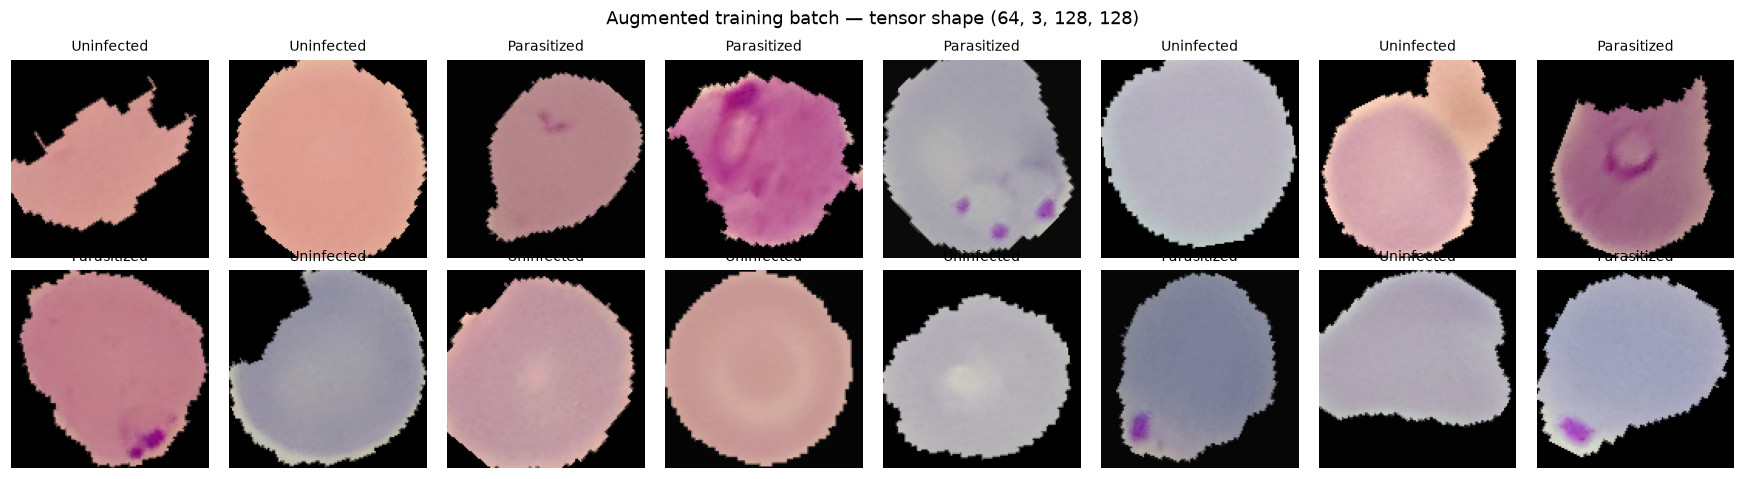

In [5]:
train_ds = MalariaCellDataset(train_df, IMG_ROOT, CLASS_TO_IDX, train_tf)
val_ds   = MalariaCellDataset(val_df,   IMG_ROOT, CLASS_TO_IDX, eval_tf)
test_ds  = MalariaCellDataset(test_df,  IMG_ROOT, CLASS_TO_IDX, eval_tf)
print(f"train={len(train_ds):,}  val={len(val_ds):,}  test={len(test_ds):,}")

def loader_opts(workers):
    o = dict(num_workers=workers, pin_memory=True)
    if workers > 0:
        o.update(persistent_workers=True, prefetch_factor=PREFETCH)
    return o

def make_loaders(seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)       # same shuffling order on every run
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                              generator=g, **loader_opts(NUM_WORKERS))
    val_loader   = DataLoader(val_ds,  batch_size=EVAL_BATCH, shuffle=False, **loader_opts(EVAL_WORKERS))
    test_loader  = DataLoader(test_ds, batch_size=EVAL_BATCH, shuffle=False, **loader_opts(EVAL_WORKERS))
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()

# Sanity check: one augmented training batch, de-normalised for display
xb, yb = next(iter(train_loader))
m, s = torch.tensor(NORM_MEAN).view(3, 1, 1), torch.tensor(NORM_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow((x * s + m).clamp(0, 1).permute(1, 2, 0).numpy()); ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
fig.suptitle(f"Augmented training batch — tensor shape {tuple(xb.shape)}")
plt.tight_layout(); plt.savefig(FIG_DIR / "augmented_batch.png"); plt.show()

## 4. The custom CNN

`ConvBlock` is the repeating unit (two Conv-BN-ReLU layers and a max pool). `MalariaCNN` stacks four blocks and adds the classifier head. Weights are initialised with **Kaiming (He) initialisation**, which is designed for ReLU networks trained from scratch.

In [6]:
class ConvBlock(nn.Module):
    # [Conv3x3 -> BatchNorm -> ReLU] x 2 -> MaxPool 2x2 (halves height and width).
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.pool(self.body(x))


class MalariaCNN(nn.Module):
    # Custom CNN: 4 conv blocks (32-64-128-256 channels) -> global average pool -> FC classifier.
    def __init__(self, num_classes=2, channels=(32, 64, 128, 256), dropout=(0.5, 0.3)):
        super().__init__()
        blocks, in_ch = [], 3
        for out_ch in channels:
            blocks.append(ConvBlock(in_ch, out_ch)); in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.gap = nn.AdaptiveAvgPool2d(1)            # 256 x 8 x 8 -> 256 x 1 x 1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout[0]),
            nn.Linear(in_ch, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout[1]),
            nn.Linear(128, num_classes),              # final fully connected layer -> 2 logits
        )
        self._init_weights()

    def _init_weights(self):
        for mod in self.modules():
            if isinstance(mod, nn.Conv2d):
                nn.init.kaiming_normal_(mod.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(mod, nn.BatchNorm2d):
                nn.init.ones_(mod.weight); nn.init.zeros_(mod.bias)
            elif isinstance(mod, nn.Linear):
                nn.init.kaiming_uniform_(mod.weight, nonlinearity="relu"); nn.init.zeros_(mod.bias)

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))

In [7]:
set_seed()
model = MalariaCNN(num_classes=len(CLASSES)).to(device, memory_format=torch.channels_last)

# Layer-by-layer summary using forward hooks (no extra packages needed)
rows, hooks = [], []
def add_hook(name, module):
    def hook(_, __, out):
        rows.append({"layer": name, "output shape": tuple(out.shape[1:]),
                     "params": sum(p.numel() for p in module.parameters())})
    hooks.append(module.register_forward_hook(hook))
for i, blk in enumerate(model.features):
    add_hook(f"Block {i + 1} (ConvBlock)", blk)
add_hook("Global average pool", model.gap)
add_hook("Classifier (FC head)", model.classifier)
model.eval()
with torch.no_grad():
    model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device).to(memory_format=torch.channels_last))
for h in hooks: h.remove()

summary = pd.DataFrame(rows); summary["params"] = summary["params"].map("{:,}".format)
display(summary)
TOTAL_PARAMS = sum(p.numel() for p in model.parameters())
TRAINABLE_PARAMS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {TOTAL_PARAMS:,} | trainable: {TRAINABLE_PARAMS:,} | "
      f"size ≈ {TOTAL_PARAMS * 4 / 1024**2:.1f} MB (FP32)")
print(model)

,layer,output shape,params
0,Block 1 (ConvBlock),"(32, 64, 64)","10,208"
1,Block 2 (ConvBlock),"(64, 32, 32)","55,552"
2,Block 3 (ConvBlock),"(128, 16, 16)","221,696"
3,Block 4 (ConvBlock),"(256, 8, 8)","885,760"
4,Global average pool,"(256, 1, 1)",0
5,Classifier (FC head),"(2,)","33,154"


Total parameters: 1,206,370 | trainable: 1,206,370 | size ≈ 4.6 MB (FP32)
MalariaCNN(
  (features): Sequential(
    (0): ConvBlock(
      (body): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (body): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): 

## 5. Training with early stopping

Each epoch makes one pass over the training set (with augmentation, dropout active and BatchNorm updating its statistics), then evaluates on the untouched validation set. We log loss, accuracy and learning rate per epoch.

* `ReduceLROnPlateau` cuts the learning rate ×0.3 when validation loss has not improved for 3 epochs.
* **Early stopping** ends training once validation loss has not improved for 8 epochs, but never before epoch 5.
* The weights with the **lowest validation loss** are kept and restored before testing, so late overfitting cannot affect the test result.

In [8]:
def to_device(x, y):
    return (x.to(device, non_blocking=True, memory_format=torch.channels_last),
            y.to(device, non_blocking=True))

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    # One pass over `loader`; trains when an optimizer is given. Returns (mean loss, accuracy).
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = to_device(x, y)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

def train_model(model, train_loader, val_loader):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=SCHED_FACTOR,
                                                           patience=SCHED_PATIENCE, min_lr=1e-6)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0

    sync(); t0 = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        te = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        lr_now = optimizer.param_groups[0]["lr"]
        scheduler.step(va_loss)
        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, lr_now]):
            history[k].append(v)

        improved = va_loss < best_loss - 1e-4
        if improved:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        print(f"ep {epoch:02d}/{MAX_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {lr_now:.1e} | {time.perf_counter() - te:5.1f}s"
              + ("  *best*" if improved else ""))
        if epoch >= MIN_EPOCHS and wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}: no val-loss improvement for {PATIENCE} epochs "
                  f"(best epoch {best_epoch}).")
            break
    sync(); train_time = time.perf_counter() - t0

    model.load_state_dict(best_state)                  # restore best-validation weights
    torch.save(best_state, CKPT_DIR / f"{RUN_NAME}.pt")
    return history, best_epoch, train_time

In [9]:
res_path, ckpt_path = RESULTS_DIR / f"{RUN_NAME}.json", CKPT_DIR / f"{RUN_NAME}.pt"
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

if not RETRAIN and res_path.exists() and ckpt_path.exists():
    saved = json.load(open(res_path))
    history, best_epoch, train_time = saved["history"], saved["best_epoch"], saved["train_time_s"]
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    print("Loaded the finished run from disk (set RETRAIN=True to train again).")
else:
    set_seed()
    model = MalariaCNN(num_classes=len(CLASSES)).to(device, memory_format=torch.channels_last)
    history, best_epoch, train_time = train_model(model, train_loader, val_loader)

epochs_run = len(history["train_loss"])
peak_gb = torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else float("nan")
print(f"\nEpochs run: {epochs_run} | best epoch: {best_epoch} | peak GPU memory: {peak_gb:.2f} GB")
print(f"TRAINING TIME: {train_time / 60:.2f} min ({train_time / epochs_run:.1f} s/epoch)")

ep 01/100 | train loss 0.2295 acc 0.9189 | val loss 0.1329 acc 0.9567 | lr 1.0e-03 |  19.9s  *best*
ep 02/100 | train loss 0.1549 acc 0.9517 | val loss 0.1317 acc 0.9564 | lr 1.0e-03 |   6.5s  *best*
ep 03/100 | train loss 0.1483 acc 0.9537 | val loss 0.1460 acc 0.9509 | lr 1.0e-03 |   6.8s
ep 04/100 | train loss 0.1496 acc 0.9535 | val loss 0.1334 acc 0.9605 | lr 1.0e-03 |   6.5s
ep 05/100 | train loss 0.1435 acc 0.9545 | val loss 0.1239 acc 0.9570 | lr 1.0e-03 |   6.6s  *best*
ep 06/100 | train loss 0.1379 acc 0.9553 | val loss 0.1125 acc 0.9625 | lr 1.0e-03 |   6.4s  *best*
ep 07/100 | train loss 0.1407 acc 0.9552 | val loss 0.1208 acc 0.9613 | lr 1.0e-03 |   6.4s
ep 08/100 | train loss 0.1348 acc 0.9566 | val loss 0.1180 acc 0.9600 | lr 1.0e-03 |   6.1s
ep 09/100 | train loss 0.1336 acc 0.9559 | val loss 0.1410 acc 0.9592 | lr 1.0e-03 |   6.1s
ep 10/100 | train loss 0.1292 acc 0.9576 | val loss 0.1217 acc 0.9635 | lr 1.0e-03 |   6.1s
ep 11/100 | train loss 0.1192 acc 0.9604 | val l

## 6. Learning curves and over/underfitting check
**Overfitting** shows up as training loss that keeps falling while validation loss rises; **underfitting** shows up as both losses staying high. The dashed line marks the restored best epoch.

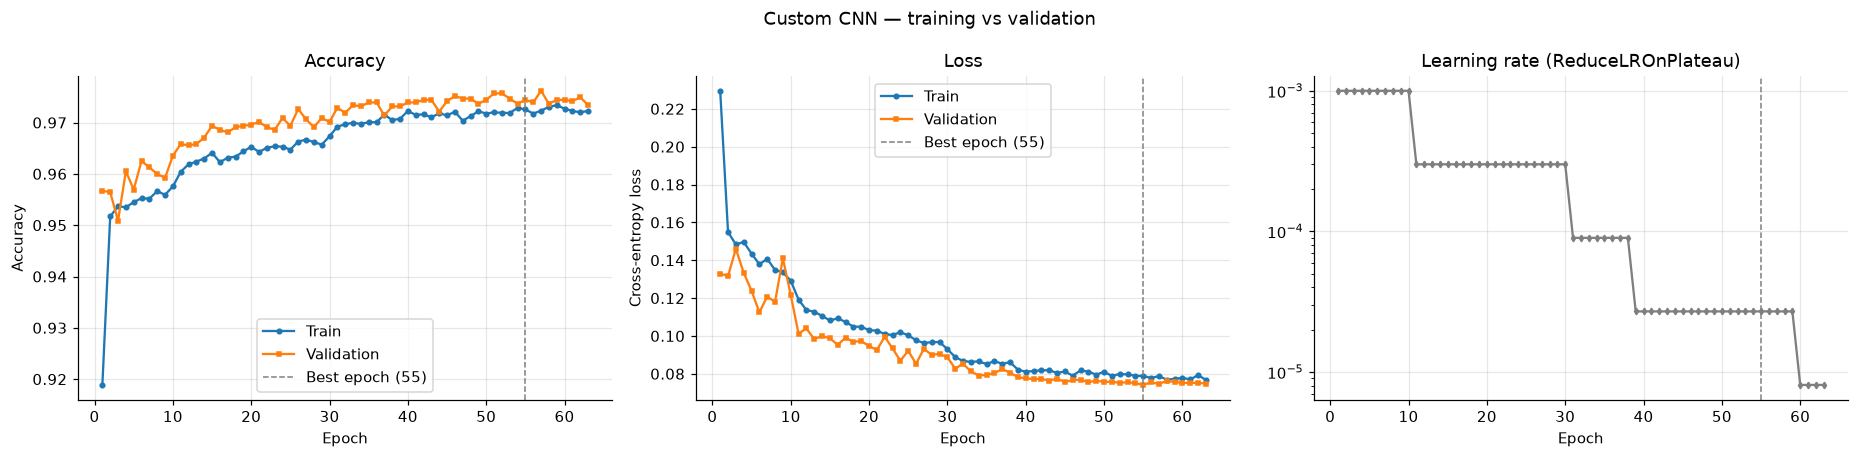

At best epoch 55: train acc 0.9726 | val acc 0.9744 | gap -0.19 pp
Val loss rose by +0.0008 between the best epoch and the last epoch (no meaningful late overfitting).
Diagnosis: good fit — training and validation accuracy agree closely.


In [10]:
ep = np.arange(1, epochs_run + 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(ep, history["train_acc"], "o-", ms=3, label="Train")
axes[0].plot(ep, history["val_acc"], "s-", ms=3, label="Validation")
axes[0].set_title("Accuracy"); axes[0].set_ylabel("Accuracy")
axes[1].plot(ep, history["train_loss"], "o-", ms=3, label="Train")
axes[1].plot(ep, history["val_loss"], "s-", ms=3, label="Validation")
axes[1].set_title("Loss"); axes[1].set_ylabel("Cross-entropy loss")
axes[2].plot(ep, history["lr"], "d-", ms=3, color="tab:gray")
axes[2].set_yscale("log"); axes[2].set_title("Learning rate (ReduceLROnPlateau)")
for ax in axes:
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
    ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
axes[0].legend(); axes[1].legend()
fig.suptitle("Custom CNN — training vs validation")
plt.tight_layout(); plt.savefig(FIG_DIR / "custom_cnn_curves.png"); plt.show()

b = best_epoch - 1
gap = history["train_acc"][b] - history["val_acc"][b]
late = history["val_loss"][-1] - history["val_loss"][b]
print(f"At best epoch {best_epoch}: train acc {history['train_acc'][b]:.4f} | val acc {history['val_acc'][b]:.4f} "
      f"| gap {gap * 100:+.2f} pp")
print(f"Val loss rose by {late:+.4f} between the best epoch and the last epoch "
      f"({'overfitting began after the best epoch; handled by checkpoint restore' if late > 0.01 else 'no meaningful late overfitting'}).")
if history["val_acc"][b] < 0.90:
    print("Diagnosis: possible UNDERFITTING (validation accuracy below 90%).")
elif gap > 0.02:
    print("Diagnosis: mild OVERFITTING at the selected epoch.")
elif gap < -0.005:
    print("Diagnosis: validation slightly above training — expected, since augmentation and dropout are active only in training.")
else:
    print("Diagnosis: good fit — training and validation accuracy agree closely.")

## 7. Test-set evaluation

The test set (3,948 images, never seen during training or model selection) is evaluated **once** with the restored best weights. Testing time is the wall-clock time to predict the whole test set, measured after one warm-up batch. Validation predictions are also saved here for the supplementary analysis in Section 9.

In [11]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    x0, _ = next(iter(loader))                            # warm-up (cuDNN autotune, lazy init)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        model(x0.to(device, memory_format=torch.channels_last))
    sync(); t0 = time.perf_counter()
    probs, ys = [], []
    for x, y in loader:
        x, _ = to_device(x, y)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        probs.append(torch.softmax(logits.float(), 1).cpu()); ys.append(y)
    sync(); elapsed = time.perf_counter() - t0
    probs = torch.cat(probs).numpy(); y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs, elapsed

# validation predictions (for Section 9), then free the train/val workers before testing
yv_true, _, pv, _ = predict(model, val_loader)
del train_loader, val_loader; gc.collect()

y_true, y_pred, probs, test_time = predict(model, test_loader)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
macro = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
auc = roc_auc_score((y_true == 0).astype(int), probs[:, 0])      # Parasitized = positive class
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fn, fp = int(cm[0, 1]), int(cm[1, 0])                             # missed infections / false alarms

print(f"TRAINING TIME: {train_time / 60:.2f} min ({epochs_run} epochs, {train_time / epochs_run:.1f} s/epoch)")
print(f"TESTING TIME : {test_time:.2f} s for {len(y_true):,} images ({1000 * test_time / len(y_true):.3f} ms/image)\n")
print("Classification report — Custom CNN (test set)\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))
print(f"ROC-AUC (Parasitized as positive): {auc:.4f}")
print(f"Parasitized RECALL (sensitivity): {rec[0]:.4f} -> {fn} of {int(sup[0]):,} infected test cells missed (false negatives)")
print(f"Uninfected recall (specificity) : {rec[1]:.4f} -> {fp} of {int(sup[1]):,} healthy test cells flagged (false positives)")

TRAINING TIME: 6.70 min (63 epochs, 6.4 s/epoch)
TESTING TIME : 2.12 s for 3,948 images (0.537 ms/image)

Classification report — Custom CNN (test set)

              precision    recall  f1-score   support

 Parasitized     0.9740    0.9686    0.9713      1972
  Uninfected     0.9688    0.9742    0.9715      1976

    accuracy                         0.9714      3948
   macro avg     0.9714    0.9714    0.9714      3948
weighted avg     0.9714    0.9714    0.9714      3948

ROC-AUC (Parasitized as positive): 0.9953
Parasitized RECALL (sensitivity): 0.9686 -> 62 of 1,972 infected test cells missed (false negatives)
Uninfected recall (specificity) : 0.9742 -> 51 of 1,976 healthy test cells flagged (false positives)


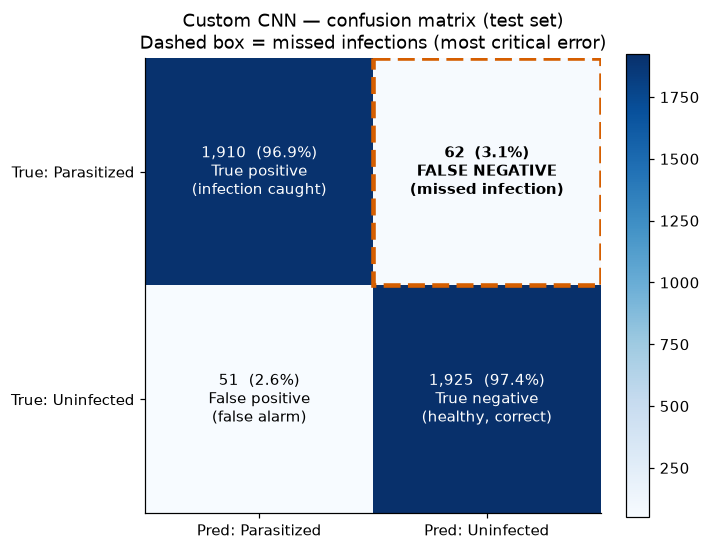

Saved: results/sub3/custom_cnn.json


In [12]:
# Confusion matrix: rows = true class, columns = predicted class (index 0 = Parasitized)
pct = cm / cm.sum(axis=1, keepdims=True)
names = [["True positive\n(infection caught)", "FALSE NEGATIVE\n(missed infection)"],
         ["False positive\n(false alarm)", "True negative\n(healthy, correct)"]]
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, ax=ax, fraction=.046)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"Pred: {c}" for c in CLASSES])
ax.set_yticks([0, 1]); ax.set_yticklabels([f"True: {c}" for c in CLASSES])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}  ({pct[i, j]:.1%})\n{names[i][j]}", ha="center", va="center", fontsize=10,
                color="white" if cm[i, j] > cm.max() / 2 else "black",
                fontweight="bold" if (i, j) == (0, 1) else "normal")
ax.add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, ec="#D55E00", lw=3, ls="--"))   # highlight FN cell
ax.set_title("Custom CNN — confusion matrix (test set)\nDashed box = missed infections (most critical error)")
plt.tight_layout(); plt.savefig(FIG_DIR / "custom_cnn_confusion.png"); plt.show()

results = {
    "run": RUN_NAME, "model": "Custom CNN (from scratch)", "mode": "Trained from scratch",
    "total_params": TOTAL_PARAMS, "trainable_params": TRAINABLE_PARAMS,
    "epochs_run": epochs_run, "best_epoch": best_epoch, "train_time_s": train_time,
    "test_time_s": test_time, "ms_per_image": 1000 * test_time / len(y_true), "peak_gpu_gb": peak_gb,
    "test_accuracy": acc, "macro_precision": macro[0], "macro_recall": macro[1], "macro_f1": macro[2],
    "precision_parasitized": prec[0], "recall_parasitized": rec[0], "f1_parasitized": f1[0],
    "precision_uninfected": prec[1], "recall_uninfected": rec[1], "f1_uninfected": f1[1],
    "auc": auc, "confusion_matrix": cm.tolist(), "false_negatives": fn, "false_positives": fp,
    "best_val_acc": history["val_acc"][best_epoch - 1], "best_val_loss": history["val_loss"][best_epoch - 1],
    "train_acc_at_best": history["train_acc"][best_epoch - 1],
    "history": history, "config": CONFIG,
}
json.dump(results, open(res_path, "w"), indent=1)
print("Saved:", res_path)

## 8. Error analysis: what does the model get wrong?
Looking at the misclassified test cells shows whether the errors are *understandable* (faint or tiny parasites, staining artefacts, possible label noise) or *systematic*. The number above each image is the model's predicted probability of `Parasitized`.

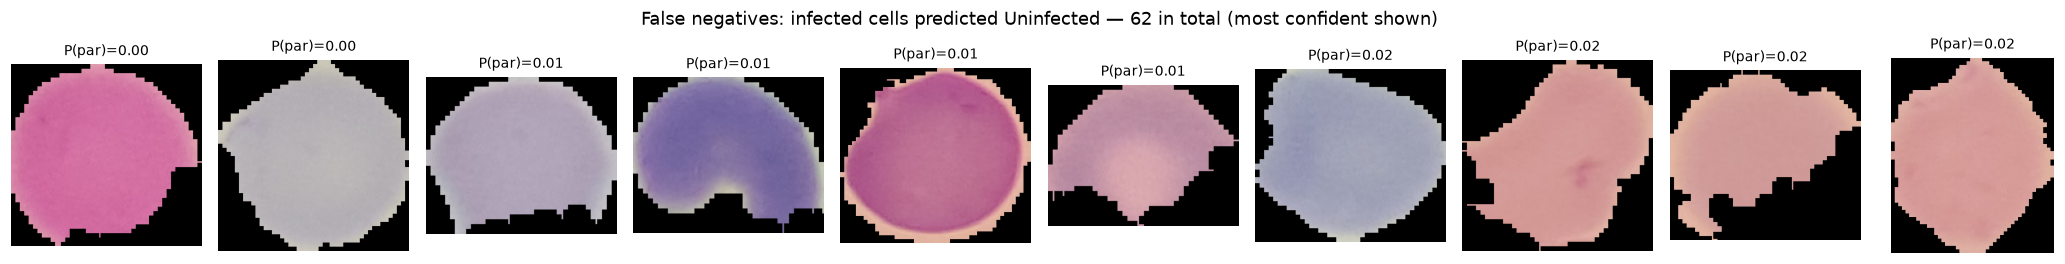

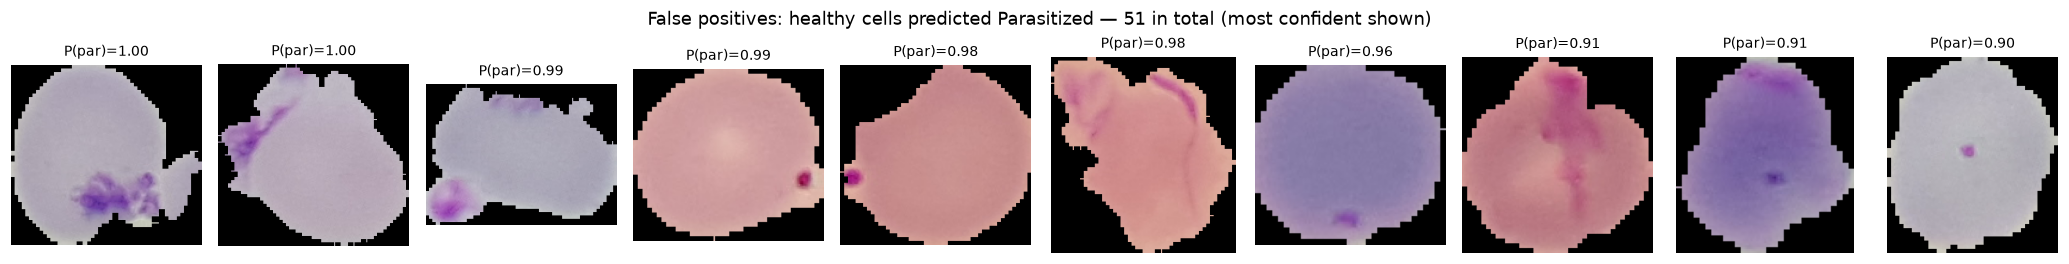

In [13]:
def show_errors(mask, title, fname, n=10):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        print(f"No {title.lower()} — nothing to show."); return
    # most confident mistakes first
    order = idx[np.argsort(-np.abs(probs[idx, 0] - 0.5))][:n]
    cols = min(n, len(order))
    fig, axes = plt.subplots(1, cols, figsize=(1.9 * cols, 2.4), squeeze=False)
    for ax, i in zip(axes[0], order):
        ax.imshow(Image.open(IMG_ROOT / test_df.relpath[i]).convert("RGB"))
        ax.set_title(f"P(par)={probs[i, 0]:.2f}", fontsize=9); ax.axis("off")
    fig.suptitle(f"{title} — {len(idx)} in total (most confident shown)")
    plt.tight_layout(); plt.savefig(FIG_DIR / fname); plt.show()

show_errors((y_true == 0) & (y_pred == 1), "False negatives: infected cells predicted Uninfected", "false_negatives.png")
show_errors((y_true == 1) & (y_pred == 0), "False positives: healthy cells predicted Parasitized", "false_positives.png")

## 9. Supplementary: clinical operating point

All reported metrics above use the standard decision rule (predict `Parasitized` when its probability is ≥ 0.5). In screening, a missed infection costs more than a false alarm, so a lower threshold may be preferable. To avoid tuning on the test set, we **choose thresholds on the validation set** for target sensitivities and only then measure them on the test set. This is an extra analysis and does not replace the main results.

In [14]:
def metrics_at(th, yt, p):
    pred_par = p[:, 0] >= th
    tp = np.sum(pred_par & (yt == 0)); fn_ = np.sum(~pred_par & (yt == 0))
    fp_ = np.sum(pred_par & (yt == 1)); tn = np.sum(~pred_par & (yt == 1))
    return dict(recall_par=tp / (tp + fn_), precision_par=tp / max(tp + fp_, 1),
                specificity=tn / (tn + fp_), accuracy=(tp + tn) / len(yt), missed=int(fn_), false_alarms=int(fp_))

fpr_v, tpr_v, thr_v = roc_curve((yv_true == 0).astype(int), pv[:, 0])
rows = [{"rule": "Default (0.50)", "threshold": 0.5, **metrics_at(0.5, y_true, probs)}]
for target in [0.98, 0.99]:
    th = float(thr_v[np.argmax(tpr_v >= target)])          # highest threshold reaching the target on validation
    th = min(th, 1.0)
    rows.append({"rule": f"Val recall ≥ {target:.0%}", "threshold": round(th, 4), **metrics_at(th, y_true, probs)})
op = pd.DataFrame(rows)
for c in ["recall_par", "precision_par", "specificity", "accuracy"]:
    op[c] = (100 * op[c]).round(2)
display(op.rename(columns={"recall_par": "Parasitized recall (%)", "precision_par": "Parasitized precision (%)",
                           "specificity": "Specificity (%)", "accuracy": "Accuracy (%)",
                           "missed": "Missed infections", "false_alarms": "False alarms"}))

,rule,threshold,Parasitized recall (%),Parasitized precision (%),Specificity (%),Accuracy (%),Missed infections,False alarms
0,Default (0.50),0.5000,96.86,97.40,97.42,97.14,62,51
1,Val recall ≥ 98%,0.3517,97.62,96.06,96.00,96.81,47,79
2,Val recall ≥ 99%,0.1475,98.43,92.47,92.00,95.21,31,158


## 10. Comparison with the Submission 2 pretrained models
All models were evaluated on the **same test images** from the same split, so the numbers are directly comparable.

In [15]:
rows = []
for p in sorted(Path("./results/sub2").glob("*.json")):
    if p.name.startswith("summary"):
        continue
    r = json.load(open(p))
    rows.append(r)
rows.append(results)
cmp_df = pd.DataFrame([{
    "Model": r["model"], "Mode": r["mode"],
    "Trainable params": f"{r['trainable_params'] / 1e6:.2f} M" if r["trainable_params"] >= 1e5 else f"{r['trainable_params']:,}",
    "Accuracy (%)": round(100 * r["test_accuracy"], 2), "Macro F1 (%)": round(100 * r["macro_f1"], 2),
    "Parasitized recall (%)": round(100 * r["recall_parasitized"], 2), "AUC": round(r["auc"], 4),
    "Train time (min)": round(r["train_time_s"] / 60, 1), "ms / image": round(r["ms_per_image"], 3),
} for r in rows]).sort_values("Macro F1 (%)", ascending=False).reset_index(drop=True)

def to_markdown(df):
    head = "| " + " | ".join(df.columns) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([head, sep] + body)

if len(rows) == 1:
    print("No Submission 2 results found in results/sub2/ — showing the custom CNN only.")
display(Markdown("### Test-set comparison (sorted by macro F1)\n\n" + to_markdown(cmp_df)))
cmp_df.to_csv(RESULTS_DIR / "comparison_with_sub2.csv", index=False)

### Test-set comparison (sorted by macro F1)

| Model | Mode | Trainable params | Accuracy (%) | Macro F1 (%) | Parasitized recall (%) | AUC | Train time (min) | ms / image |
|---|---|---|---|---|---|---|---|---|
| DenseNet-121 | Fine-tuned | 6.96 M | 97.7 | 97.69 | 97.31 | 0.9968 | 16.4 | 0.834 |
| MobileNetV2 | Fine-tuned | 2.23 M | 97.29 | 97.29 | 97.26 | 0.9962 | 7.6 | 0.802 |
| ResNet-50 | Fine-tuned | 23.51 M | 97.29 | 97.29 | 97.16 | 0.9964 | 14.4 | 0.795 |
| Custom CNN (from scratch) | Trained from scratch | 1.21 M | 97.14 | 97.14 | 96.86 | 0.9953 | 6.7 | 0.537 |
| ResNet-50 | Frozen (no fine-tuning) | 4,098 | 93.41 | 93.41 | 92.6 | 0.9781 | 8.4 | 0.955 |
| DenseNet-121 | Frozen (no fine-tuning) | 2,050 | 92.43 | 92.43 | 91.28 | 0.9757 | 9.7 | 1.151 |
| MobileNetV2 | Frozen (no fine-tuning) | 2,562 | 92.33 | 92.32 | 91.43 | 0.9737 | 6.9 | 1.106 |

In [16]:
# Auto-generated summary of this run's numbers (always matches the outputs above)
bench = max((r for r in rows if r is not results), key=lambda r: r["macro_f1"], default=None)
lines = [
    f"- **Training vs. validation (best epoch {best_epoch} of {epochs_run}):** train accuracy "
    f"{100 * results['train_acc_at_best']:.2f}%, validation accuracy {100 * results['best_val_acc']:.2f}% "
    f"(gap {100 * (results['train_acc_at_best'] - results['best_val_acc']):+.2f} pp).",
    f"- **Test performance:** accuracy {100 * acc:.2f}%, macro F1 {100 * macro[2]:.2f}%, AUC {auc:.4f} — "
    f"{100 * (acc - results['best_val_acc']):+.2f} pp versus validation accuracy.",
    f"- **Parasitized recall: {100 * rec[0]:.2f}%** — {fn} of {int(sup[0]):,} infected cells missed; "
    f"Parasitized precision {100 * prec[0]:.2f}% ({fp} false alarms).",
    f"- **Cost:** {TOTAL_PARAMS / 1e6:.2f} M parameters, training {train_time / 60:.1f} min, "
    f"testing {test_time:.2f} s ({1000 * test_time / len(y_true):.3f} ms/image).",
]
if bench:
    lines.append(f"- **Versus best pretrained model ({bench['model']}, {bench['mode']}):** accuracy "
                 f"{100 * (acc - bench['test_accuracy']):+.2f} pp, Parasitized recall "
                 f"{100 * (rec[0] - bench['recall_parasitized']):+.2f} pp, with "
                 f"{bench['trainable_params'] / TOTAL_PARAMS:.1f}× fewer parameters to train.")
display(Markdown("### Key numbers of this run\n\n" + "\n".join(lines)))

### Key numbers of this run

- **Training vs. validation (best epoch 55 of 63):** train accuracy 97.26%, validation accuracy 97.44% (gap -0.19 pp).
- **Test performance:** accuracy 97.14%, macro F1 97.14%, AUC 0.9953 — -0.30 pp versus validation accuracy.
- **Parasitized recall: 96.86%** — 62 of 1,972 infected cells missed; Parasitized precision 97.40% (51 false alarms).
- **Cost:** 1.21 M parameters, training 6.7 min, testing 2.12 s (0.537 ms/image).
- **Versus best pretrained model (DenseNet-121, Fine-tuned):** accuracy -0.56 pp, Parasitized recall -0.46 pp, with 5.8× fewer parameters to train.

## 11. Evaluation report

**Training vs. testing performance.** The learning curves (Section 6) and the key numbers above compare training, validation and test accuracy. Training accuracy is measured on *augmented* images with dropout active, so it can sit slightly below validation accuracy without any problem. The meaningful checks are these: validation loss should stop improving at a clear best epoch, and test accuracy should be close to validation accuracy. A small validation-to-test difference shows the model generalises to unseen smear photographs. Our split keeps every photograph inside a single subset, so this is an honest estimate rather than one inflated by near-duplicate cells. Early stopping, the learning-rate schedule, dropout, weight decay and the best-checkpoint restore together keep the selected model at the point where it generalises best. Any rise in validation loss after that epoch did not reach the tested model.

**Parasitized recall is the most critical metric.** This is a medical screening task, and the two possible errors are not equally costly:
* A **false negative** (an infected cell predicted `Uninfected`) can lead to an untreated malaria infection, which can progress rapidly and become life-threatening.
* A **false positive** (a healthy cell flagged as `Parasitized`) leads at worst to a second look by a microscopist or a confirmatory test.

We therefore judge the model first by its **recall on the Parasitized class** (sensitivity): the share of truly infected cells it catches. In the confusion matrix this is the **top-right cell** (true Parasitized, predicted Uninfected), highlighted with a dashed box. Accuracy and macro F1 summarise overall quality, but because the classes are balanced, a model could trade missed infections for fewer false alarms and keep the same accuracy. Recall exposes that trade-off. The error gallery (Section 8) shows what the remaining misses look like, and Section 9 shows how far recall can be raised by lowering the decision threshold. That threshold is chosen on validation data only, at the cost of more false alarms. This is the setting a real screening tool would use.

**Conclusion.** Trained from random weights on the same leakage-safe split, the custom CNN comes close to the best fine-tuned pretrained model from Submission 2 (see the comparison in Section 10), while using a fraction of the parameters and training time and running faster at test time. This shows that, for a focused two-class texture problem like malaria cell screening, a compact purpose-built network is a practical alternative to large ImageNet models, which matters for low-cost or smartphone-based deployment. Its main remaining weakness is the small number of missed infections shown in Section 8. In practice that number can be reduced further by lowering the decision threshold (Section 9), accepting more false alarms that a microscopist would re-check.